# 01 — Dataset Comparison, Label Audit & Cross-Network Test

Datasets compared:
1. **CIC-IDS2017** (UNB CIC — converted to Zeek)
2. **UWF-ZeekData** (University of West Florida — 2024 & 2025)
3. **AIT-LDSv2** (Austrian Institute of Technology — 2022 `russellmitchell`, converted to Zeek)
4. **TON_IoT** (UNSW Canberra — Network CSV)
5. **UNSW-NB15** (UNSW Canberra — converted to Zeek)

**Goal:** compare them side by side, check that their labels are right, and score the production `zeek-hybrid-m3-v1` model on every test set without leaks.

## 1. How realistic is each dataset's benign & host traffic?
We check benign TCP payload bytes (to catch idle labs) and 60-second per-host burst rates (to catch synthetic traffic generators).

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from cybershield.ml.train_zeek import MODELS_DIR, evaluate_test_set
from cybershield.ml.zeek_features import (
    ZEEK_HYBRID_FEATURES,
    load_ait_zeek,
    load_cic2017_zeek,
    load_ton_iot,
    load_unsw_zeek,
    load_uwf_zeek,
)


def summarize(name: str, df: pd.DataFrame, has_ts: bool = True) -> dict:
    btcp = df[(df["label"] == 0) & (df["proto"] == "tcp")]
    row = {
        "Dataset": name,
        "Flows": len(df),
        "Attack %": round(df["label"].mean() * 100, 1),
        "Benign TCP": len(btcp),
        "Benign TCP Med Bytes": round(float((btcp["orig_bytes"].fillna(0) + btcp["resp_bytes"].fillna(0)).median()), 1) if len(btcp) else 0.0,
        "Has ts?": "Yes" if has_ts else "No",
    }
    for cls, tag in [(0, "Benign"), (1, "Attack")]:
        for col, short in [("host_conn_60s", "conn/60s"), ("host_uniq_ports_60s", "ports/60s")]:
            row[f"{tag} Med {short}"] = round(float(df.loc[df["label"] == cls, col].median()), 1) if has_ts else np.nan
    return row


cic = load_cic2017_zeek()
uwf24 = load_uwf_zeek("UWF-ZeekData24")
uwf_f24 = load_uwf_zeek("UWF-ZeekDataFall24-2")
uwf_s25_1 = load_uwf_zeek("UWF-ZeekDataSum25-1")
uwf_s25_2 = load_uwf_zeek("UWF-ZeekDataSum25-2")
ton = load_ton_iot()
ait_z = load_ait_zeek()
unsw_z = load_unsw_zeek()

comp_df = pd.DataFrame([
    summarize("CIC-IDS2017 (5d Zeek)", cic),
    summarize("UWF-ZeekData24", uwf24),
    summarize("UWF-ZeekDataFall24-2", uwf_f24),
    summarize("UWF-ZeekDataSum25-1", uwf_s25_1),
    summarize("UWF-ZeekDataSum25-2", uwf_s25_2),
    summarize("AIT-LDSv2 (2022 Zeek)", ait_z),
    summarize("TON_IoT (CSV)", ton, has_ts=False),
    summarize("UNSW-NB15 (20GB Zeek)", unsw_z),
])
display(comp_df)

,Dataset,Flows,Attack %,Benign TCP,Benign TCP Med Bytes,Has ts?,Benign Med conn/60s,Benign Med ports/60s,Attack Med conn/60s,Attack Med ports/60s
0,CIC-IDS2017 (5d Zeek),2109238,25.3,537520,4653.0,Yes,260.0,4.0,7736.0,1.0
1,UWF-ZeekData24,1898613,49.5,67447,0.0,Yes,26.0,1.0,210.0,1.0
2,UWF-ZeekDataFall24-2,2901532,49.8,109789,0.0,Yes,4.0,1.0,85840.0,39961.0
3,UWF-ZeekDataSum25-1,1149977,49.8,68,10615.0,Yes,3.0,1.0,5959.0,3.0
4,UWF-ZeekDataSum25-2,1868679,50.0,2048,177636.0,Yes,8.0,1.0,56522.0,22140.0
5,AIT-LDSv2 (2022 Zeek),254947,98.5,14,1983.5,Yes,1.0,1.0,5864.0,2.0
6,TON_IoT (CSV),211043,76.3,18203,0.0,No,NaN,NaN,NaN,NaN
7,UNSW-NB15 (20GB Zeek),393113,1.1,281340,5266.0,Yes,134.0,58.0,32.0,8.0


## 2. Normal vs. attack host bursts
`UNSW-NB15`'s Normal hosts are **busier than its attackers** (134 conn/min & 58 ports/min vs. 32 & 8).

We first called this an IXIA artifact and excluded UNSW. The more useful reading: real LANs also have busy benign hosts (DNS servers, proxies, NAS, backup servers). UNSW shows what our model does with them (section 4).

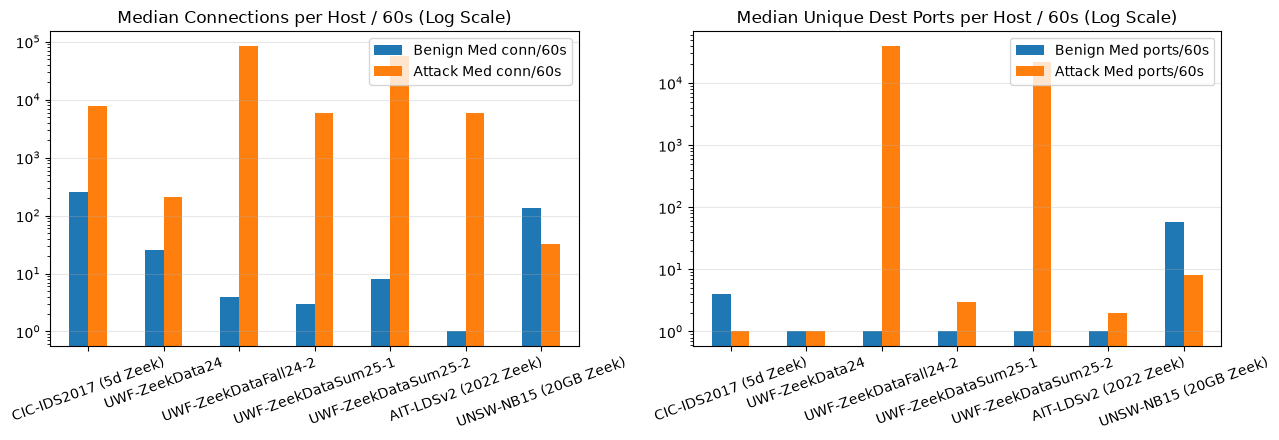

In [2]:
plot_df = comp_df.dropna(subset=["Benign Med conn/60s"]).set_index("Dataset")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, cols, title in [
    (axes[0], ["Benign Med conn/60s", "Attack Med conn/60s"], "Median Connections per Host / 60s (Log Scale)"),
    (axes[1], ["Benign Med ports/60s", "Attack Med ports/60s"], "Median Unique Dest Ports per Host / 60s (Log Scale)"),
]:
    plot_df[cols].plot(kind="bar", ax=ax, rot=20)
    ax.set_title(title)
    ax.set_yscale("log")
    ax.set_xlabel("")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Label audit (fixed in `zeek_features.py`)
- **CIC-IDS2017:** the Parquet labels came from joining Zeek flows to the CICFlowMeter CSVs, which have published errors (Engelen et al. 2021). `load_cic2017_zeek()` now labels from **UNB's attack schedule** (`CIC_ATTACK_SCHEDULE`): a flow is an attack if it runs between the attacker and victim IPs inside the attack window. All CSV attacks are kept. ~75k flows are added, mostly the infiltration victim `192.168.10.8` port-scanning every internal host on Thursday 14:33–15:45, which the CSV called BENIGN.
- **AIT-LDSv2:** the old rule only counted flows *from* an attacker IP. dnsteal exfiltration is DNS sent *to* the attacker's server, so 84% of the "benign" rows were exfiltration. Now either end counts. The PCAPs were captured on the attacker host, so AIT is ~98.5% attack: **a recall-only test**.

In [3]:
# CIC-IDS2017: old CICFlowMeter CSV labels vs. UNB attack-schedule labels (now used everywhere)
print(f"Agreement: {(cic['label'] == cic['label_csv']).mean():.2%}")
display(pd.crosstab(cic["label_csv"], cic["label"], rownames=["CSV label"], colnames=["schedule label"]))
flipped = cic[(cic["label_csv"] == 0) & (cic["label"] == 1)]
display(flipped["attack_type"].value_counts().rename("CSV said BENIGN, schedule says attack").to_frame())

# AIT-LDSv2: what the old src-only rule called "benign"
old_benign = ait_z[~ait_z["src_ip"].isin({"10.9.0.10", "192.168.230.122"})]
display(old_benign["attack_type"].value_counts().rename("old 'benign' rows, by new label").to_frame())

Agreement: 96.43%


schedule label,0,1
CSV label,,
0,1575008,75197
1,0,459033


,"CSV said BENIGN, schedule says attack"
attack_type,
Infiltration - Portscan,73828
PortScan,796
DoS Hulk,537
Infiltration,26
Web Attack - Brute Force,7
FTP-Patator,2
DoS slowloris,1


,"old 'benign' rows, by new label"
attack_type,
AIT-dnsteal exfil,19985
BENIGN,3858
AIT-red team,10


## 4. Production model on every test set
- **CIC rows** are **leave-one-day-out** (from `train_zeek.py`): each day is scored by a model that never saw that day, so its attack types are new. (The old random split put neighbouring minutes of the same attack on both sides and reported 0.994 F1.)
- **Host-min**: one decision per host per minute (attack if any flow is; flagged if any flow is), so a 100k-flow scan counts once.
- **Macro recall**: mean recall over attack types, so every attack type counts equally.
- Threshold 0.5.

In [4]:
report = json.loads((MODELS_DIR / "zeek-hybrid-m3-v1.metrics.json").read_text())
model = joblib.load(MODELS_DIR / "zeek-hybrid-m3-v1.joblib")


def row(name: str, r: dict) -> dict:
    return {
        "Test Set": name,
        "Flow Recall": r["flow"]["recall"],
        "Flow FPR": r["flow"]["false_positive_rate"],
        "Host-min Recall": r["host_minute"]["recall"],
        "Host-min FPR": r["host_minute"]["false_positive_rate"],
        "Macro Recall (by attack type)": r["macro_recall"],
    }


rows = [row(f"CIC {d.removeprefix('cic_')} (left out)", r) for d, r in report["cic_leave_one_day_out"].items()]
for name, tdf in {
    "UWF-Sum25-1 (unseen 2025)": uwf_s25_1,
    "UWF-Sum25-2 (unseen 2025)": uwf_s25_2,
    "AIT-LDSv2 (zero-shot, recall-only)": ait_z,
    "UNSW-NB15 (zero-shot)": unsw_z,
}.items():
    rows.append(row(name, evaluate_test_set(tdf, model.predict_proba(tdf[ZEEK_HYBRID_FEATURES])[:, 1])))
display(pd.DataFrame(rows))

,Test Set,Flow Recall,Flow FPR,Host-min Recall,Host-min FPR,Macro Recall (by attack type)
0,CIC tuesday (left out),0.5689,0.00027,0.5276,0.00492,0.4975
1,CIC wednesday (left out),0.9078,0.00120,0.9710,0.00810,0.5812
2,CIC thursday (left out),0.9802,0.01098,0.7070,0.00433,0.7681
3,CIC friday (left out),0.9774,0.00005,0.0789,0.00072,0.6826
4,UWF-Sum25-1 (unseen 2025),0.1497,0.00000,0.3058,0.00000,0.4110
5,UWF-Sum25-2 (unseen 2025),0.9997,0.00001,0.9688,0.00002,0.9998
6,"AIT-LDSv2 (zero-shot, recall-only)",0.9180,0.00285,0.0108,0.00143,0.4987
7,UNSW-NB15 (zero-shot),0.0734,0.50580,0.3886,0.87064,0.0439


### What the numbers say
- **Known attack types are caught; new ones mostly aren't.** Each left-out CIC day contains attack types absent from training: SSH-Patator 0.6%, DoS GoldenEye 4.7%, Bot 5.5%, SQLi 0% (see notebook 02).
- **Per-flow scores flatter the model.** Friday is 97.7% per flow but 7.9% per host-minute: DDoS/PortScan floods are caught, while Bot beacons (most attack host-minutes) are missed.
- **UWF-Sum25-1 is unstable.** Its "Recon" is ~6k *successful* short connections/min to ~3 ports, unlike any training data. Recall went 80% → 15% when the CIC labels were fixed and swung 15–80% across small training changes. Don't treat it as a benchmark.
- **AIT:** red-team scans/exploits 99.7%, **dnsteal DNS exfiltration 0%**. Host-minute recall is 1.1% because the exfil runs for days.
- **UNSW: 50.6% flow FPR, 87% host-minute FPR.** The model learned "busy host / many ports = attack". Fixing the CIC scan labels made that worse (it was 8.5%). On a real LAN, busy benign hosts need allowlisting or per-host baselines.

## 5. Dataset Sources, Pros, Cons & Verdict

| Dataset | Source | Role | Pros | Cons / Flaws | Key Notes |
|---|---|---|---|---|---|
| **CIC-IDS2017** *(5d Zeek)* | [UNB](https://www.unb.ca/cic/datasets/ids-2017.html) · [HF](https://huggingface.co/datasets/bvsam/cic-ids-2017) | **Primary train; leave-one-day-out test** | Real Zeek `conn.log`; **538k real benign TCP** (SSL/HTTP/SSH/FTP, median 4.7 KB); timestamps for 60s windows; benign & 14 attack types on one LAN. | 99% of attack flows come from one IP (`172.16.0.1`) to one victim (`.50`), so IP-fanout features are a shortcut (dropped `host_uniq_ips_60s`); 2017 traffic; CSV labels had errors. | 52 GB PCAPs → 48 MB Parquet on Colab. Labels from UNB's attack schedule (96.4% agree with the CSV; +75k attack flows). |
| **UWF-ZeekData24 & Fall24-2** | [UWF](https://datasets.uwf.edu/data/) | **Co-training** | Native Zeek Parquet; 2024 captures; MITRE ATT&CK labels. | **Idle-lab benign** (92–99% UDP DNS, **0-byte** TCP); benign & attack in separate weeks. | Balanced 80k/80k chunks. Drop `label_binary == "Duplicate"` rows. |
| **UWF-Sum25-1 & Sum25-2** | [UWF](https://datasets.uwf.edu/data/) | **Unseen 2025 test** | Newer captures; tests 2024 → 2025. | Same idle benign; `Sum25-2`'s 934k attack flows come from **32 host-minutes**; `Sum25-1` "Recon" looks nothing like the training recon. | Benign FPR ≈ 0 is meaningless for a real LAN (idle benign). |
| **AIT-LDSv2** *(2022 Zeek)* | [Zenodo](https://zenodo.org/records/5789064) | **Recall-only 3rd-network test** | Real 2022 multi-step red-team chain (VPN foothold → internal sweep → WordPress crack → reverse shell → dnsteal exfil). | Both PCAPs are near-identical captures **on the attacker host**: ~98.5% attack, the rest is IPv6/mDNS noise. | Labeled attack if either end is `10.9.0.10` / `192.168.230.122`. Red team 99.7%, DNS exfil 0%. |
| **TON_IoT** *(CSV)* | [UNSW](https://research.unsw.edu.au/projects/toniot-datasets) · [HF](https://huggingface.co/datasets/codymlewis/TON_IoT_network) | **Single-flow reference** | Native Zeek columns; real benign TCP + 9 attack types. | **No `ts` timestamps** (no 60s windows); IoT sensor loop (`src_pkts == 120`); many duplicate flows. | Not usable with the Hybrid model. |
| **UNSW-NB15** *(20 GB Zeek)* | [UNSW](https://research.unsw.edu.au/projects/unsw-nb15-dataset) · [PCAP](https://huggingface.co/datasets/Mireu-Lab/UNSW-NB15) · [GT](https://huggingface.co/datasets/Mouwiya/UNSW-NB15) | **Audit of the volume bias** | 281k benign TCP flows with real payloads; busy benign hosts. | Labels look under-matched (1.1% attack vs ~12.6% in full UNSW; 1,675 of 6,159 attacker-subnet flows labeled Normal). Legacy CSV uses Argus & TTL. | `M3` flags 50.6% of its benign flows: our model's "busy host = attack" bias, not just a dataset flaw. |

## 6. How Each Dataset Was Captured (Key Insights)

1. **CIC-IDS2017** (UNB, 2017): 5 workdays in a simulated office LAN (25 user profiles) while an external attacker ran scheduled attacks. We ran **Zeek** on the 5 PCAPs (52 GB → 48 MB). Labels: UNB's published attack schedule (attacker ↔ victim IPs within each attack's time window, local time UTC-3).
2. **UWF-ZeekData** (UWF, 2024–2025): native **Zeek** on UWF's cyber range, exported to weekly Parquet with MITRE ATT&CK labels. Benign and attack were captured in **separate weeks**, and the benign weeks are an idle lab, so it is only useful as extra attack variety.
3. **AIT-LDSv2** (AIT, 2022): 4–6 day enterprise testbeds with a scripted red-team kill chain. Zenodo's `russellmitchell.zip` only has PCAPs from the attacker host (`attacker_0/logs/{dnsteal,wpdiscuz}/traffic.pcap`). We ran Zeek on them (7.1 GB → 6.7 MB, 254,947 unique flows).
4. **TON_IoT** (UNSW Canberra, 2020): IoT/IIoT + LAN cyber range logged with Zeek. The public `train_test_network.csv` drops `ts`, so 60s windows can't be built.
5. **UNSW-NB15** (UNSW Canberra, 2015): synthetic traffic from an **IXIA PerfectStorm** generator over two days. We ran Zeek on 20 of its PCAPs (393k flows) and labeled by 5-tuple + `[Stime-2s, Ltime+2s]`. The low attack share suggests that join misses many attacks; fix it before trusting UNSW recall.